# Advertising Spend → Sales Prediction

How do TV, radio and newspaper budgets relate to product sales? This notebook measures each channel's correlation with sales, fits linear-regression models on different feature sets, and uses the model to predict sales for a new budget.

**Dataset:** `data/advertising_sales_data.xlsx`: ad spend per channel and resulting sales for 200 markets (the classic *Advertising* dataset).

**Techniques:** correlation analysis, scikit-learn `LinearRegression`, R² comparison, feature scaling.

1.	What is the average amount spent on TV advertising in the dataset?

In [ ]:
import pandas as pd
df = pd.read_excel('data/advertising_sales_data.xlsx')

avg_tv = df['TV'].mean()
print("Average TV Advertising Spend:", avg_tv)

Average TV Advertising Spend: 147.0425


2.	What is the correlation between radio advertising expenditure and product sales?

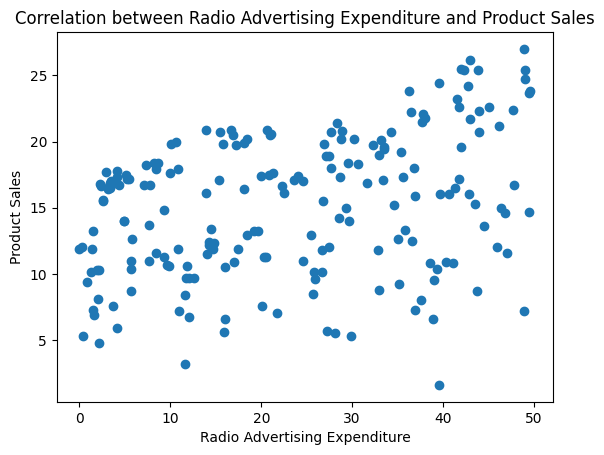

Correlation between Radio and Sales: 0.3497277129207837


In [ ]:
import matplotlib.pyplot as plt

plt.figure()
plt.scatter(df['Radio'], df['Sales'])
plt.xlabel("Radio Advertising Expenditure")
plt.ylabel("Product Sales")
plt.title("Correlation between Radio Advertising Expenditure and Product Sales")
plt.show()

radio_sales_corr = df['Radio'].corr(df['Sales'])
print("Correlation between Radio and Sales:", radio_sales_corr)



3.	Which advertising medium has the highest impact on sales based on the dataset?

In [ ]:
correlations = df[['TV','Radio','Newspaper']].corrwith(df['Sales'])
print("Correlation with Sales:")
print(correlations)


Correlation with Sales:
TV           0.901208
Radio        0.349728
Newspaper    0.157960
dtype: float64


4.	Plot a linear regression line that includes all variables (TV, Radio, Newspaper) to predict Sales, and visualize the model's predictions against the actual sales values.

R2 Score (All Predictors): 0.9029164691118196


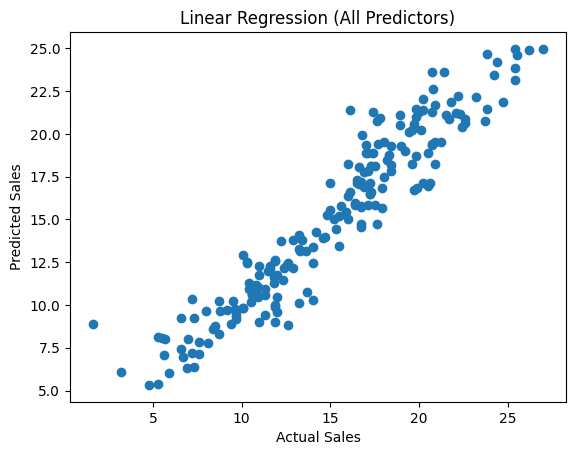

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

df = df.dropna()  # drop rows with missing values before building X and y
X = df[['TV','Radio','Newspaper']]
y = df['Sales']
#X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2,random_state=1)

model = LinearRegression()
model.fit(X, y)

prediction = model.predict(X)

r2_full = r2_score(y, prediction)
print("R2 Score (All Predictors):", r2_full)

plt.figure()
plt.scatter(y, prediction)
plt.plot()
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Linear Regression (All Predictors)")
plt.show()

How would sales be predicted for a new set of advertising expenditures: $200 on TV, $40 on Radio, and $50 on Newspaper?

In [ ]:
new_data = pd.DataFrame([[200,40,50]], columns=['TV','Radio','Newspaper'])
new_prediction = model.predict(new_data)

print("Predicted Sales:", new_prediction[0])


Predicted Sales: 19.819378160410906


6.	How does the performance of the linear regression model change when the dataset is normalized?

R2 Score (Normalized Data): 0.9029164691118196


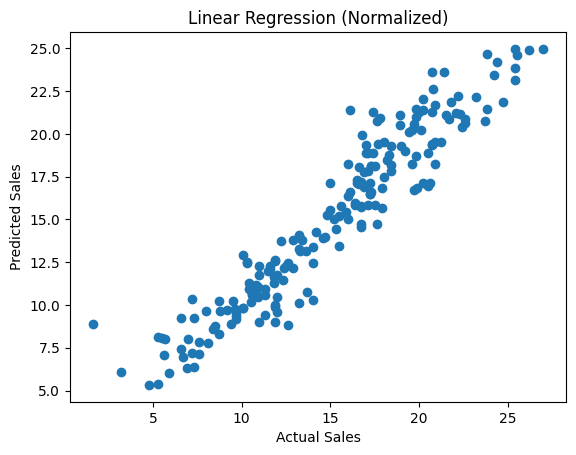

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

model_scaled = LinearRegression()
model_scaled.fit(X_scaled, y)

pred_scaled = model_scaled.predict(X_scaled)

r2_scaled = r2_score(y, pred_scaled)
print("R2 Score (Normalized Data):", r2_scaled)

plt.figure()
plt.scatter(y, pred_scaled)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Linear Regression (Normalized)")
plt.show()


What is the impact on the sales prediction when only radio and newspaper advertising expenditures are used as predictors?

R2 Score (Radio + Newspaper Only): 0.12370915572237262


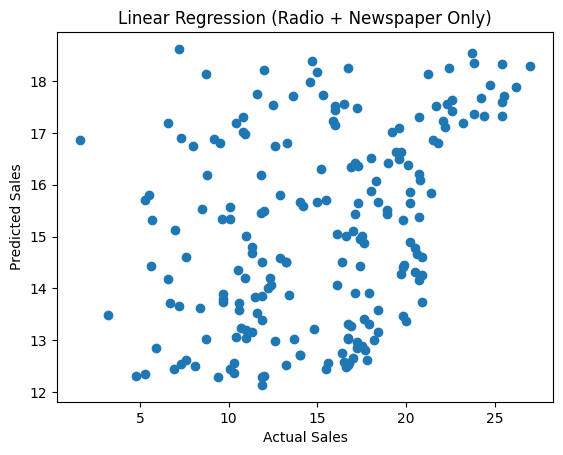

In [ ]:
X_reduced = df[['Radio','Newspaper']]

model_reduced = LinearRegression()
model_reduced.fit(X_reduced, y)

pred_reduced = model_reduced.predict(X_reduced)

r2_reduced = r2_score(y, pred_reduced)
print("R2 Score (Radio + Newspaper Only):", r2_reduced)

plt.figure()
plt.scatter(y, pred_reduced)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Linear Regression (Radio + Newspaper Only)")
plt.show()
